# Odoo Daily Sales Forecasting with ARIMA

This notebook builds a practical **AutoRegressive Integrated Moving Average (ARIMA)** workflow using daily sales revenue exported from Odoo.

Workflow: load data → fill daily timeline → visualize → train/test split → naive baseline → stationarity → choose `p,d,q` → train ARIMA → evaluate → walk-forward validation → 30-day forecast.


## PostgreSQL query to export `daily_sales.csv`

Run this in pgAdmin and export the result as `daily_sales.csv`.

```sql
WITH dates AS (
    SELECT generate_series(
        '2025-01-06'::date,
        '2026-08-07'::date,
        INTERVAL '1 day'
    )::date AS sale_date
),
sales AS (
    SELECT
        (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,
        SUM(amount_total) AS daily_sales_total
    FROM sale_order
    WHERE state IN ('sale', 'done')
      AND (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date >= '2025-01-06'
      AND (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date <= '2026-08-07'
    GROUP BY 1
)
SELECT
    d.sale_date,
    COALESCE(s.daily_sales_total, 0) AS daily_sales_total
FROM dates d
LEFT JOIN sales s ON d.sale_date = s.sale_date
ORDER BY d.sale_date;
```


## Install required libraries

In [1]:
!pip install pandas numpy matplotlib statsmodels scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imports

In [3]:
import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA, ARIMAResults

from sklearn.metrics import mean_absolute_error, mean_squared_error


## Load the exported CSV

In [4]:
df = pd.read_csv(\"../input/../input/johns_daily_sales.csv\")
df.head()


,sale_date,daily_sales_total
0,2025-01-06,5796829.52
1,2025-01-07,903355.24
2,2025-01-08,121297.50
3,2025-01-09,0.00
4,2025-01-10,357332.86


## Inspect and prepare the data

In [4]:
print("Shape:", df.shape)
print(df.info())

df["sale_date"] = pd.to_datetime(df["sale_date"])
df = df.sort_values("sale_date").set_index("sale_date")
df.head()


Shape: (579, 2)
<class 'pandas.DataFrame'>
RangeIndex: 579 entries, 0 to 578
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sale_date          579 non-null    str    
 1   daily_sales_total  579 non-null    float64
dtypes: float64(1), str(1)
memory usage: 9.2 KB
None


,daily_sales_total
sale_date,
2025-01-06,5796829.52
2025-01-07,903355.24
2025-01-08,121297.50
2025-01-09,0.00
2025-01-10,357332.86


## Verify timeline and enforce daily frequency

In [5]:
print("First date:", df.index.min())
print("Last date :", df.index.max())
print("Rows      :", len(df))

expected_days = (df.index.max() - df.index.min()).days + 1
print("Expected calendar days:", expected_days)

df = df.asfreq("D")
print("\nMissing before fill:")
print(df.isnull().sum())

df["daily_sales_total"] = df["daily_sales_total"].fillna(0)

print("\nMissing after fill:")
print(df.isnull().sum())


First date: 2025-01-06 00:00:00
Last date : 2026-08-07 00:00:00
Rows      : 579
Expected calendar days: 579

Missing before fill:
daily_sales_total    0
dtype: int64

Missing after fill:
daily_sales_total    0
dtype: int64


> Important: filling a missing date with zero assumes that no sales occurred that day. Confirm this before production use.

## Basic statistics

In [6]:
print(df["daily_sales_total"].describe())

zero_days = (df["daily_sales_total"] == 0).sum()
print("\nZero-sales days:", zero_days)
print("Zero-sales percentage:", round(zero_days / len(df) * 100, 2), "%")


count    5.790000e+02
mean     7.111291e+05
std      1.808549e+06
min      0.000000e+00
25%      0.000000e+00
50%      6.024900e+04
75%      5.517437e+05
max      2.184477e+07
Name: daily_sales_total, dtype: float64

Zero-sales days: 205
Zero-sales percentage: 35.41 %


## Plot daily sales

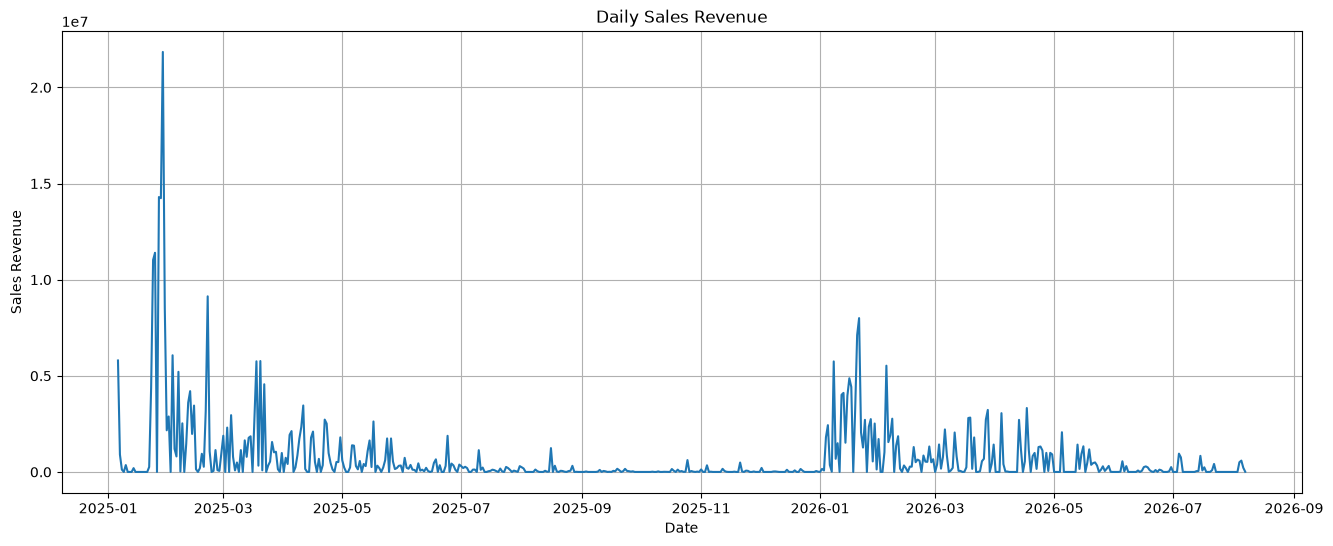

In [7]:
plt.figure(figsize=(16, 6))
plt.plot(df.index, df["daily_sales_total"])
plt.title("Daily Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Sales Revenue")
plt.grid(True)
plt.show()


## Log-transformed plot

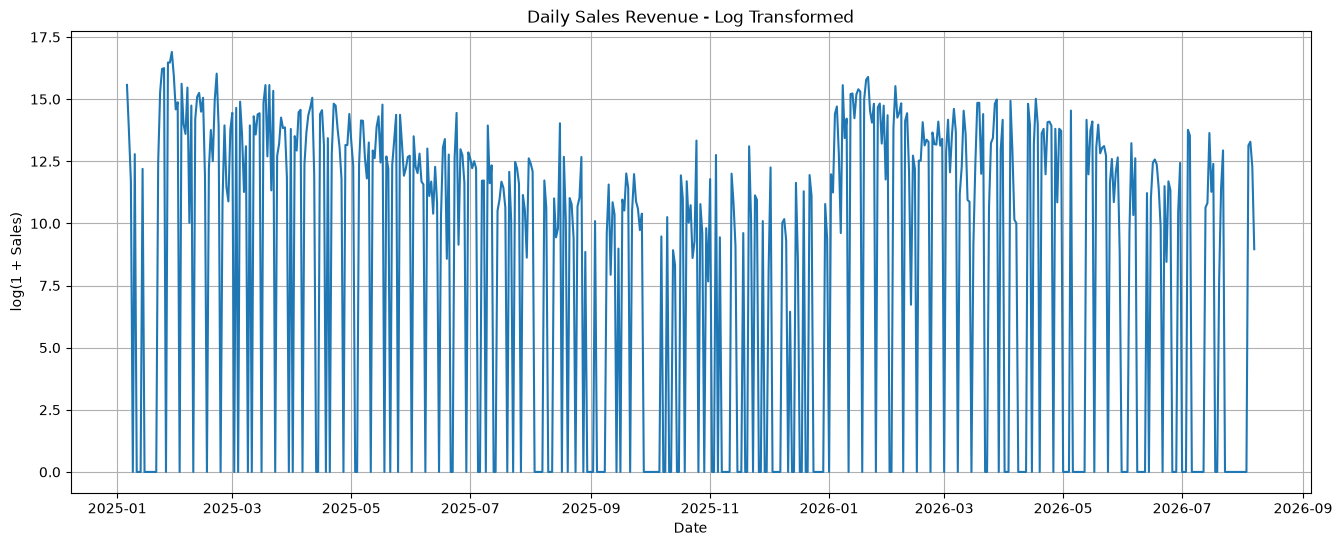

In [8]:
plt.figure(figsize=(16, 6))
plt.plot(df.index, np.log1p(df["daily_sales_total"]))
plt.title("Daily Sales Revenue - Log Transformed")
plt.xlabel("Date")
plt.ylabel("log(1 + Sales)")
plt.grid(True)
plt.show()


## Monthly sales view

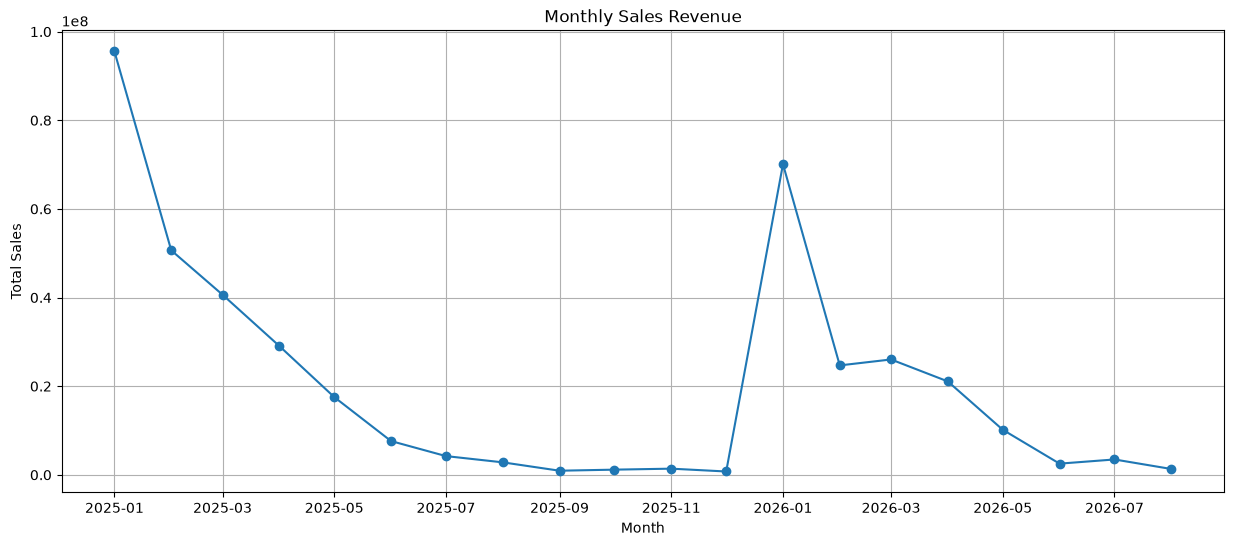

sale_date
2025-01-01    95524680.20
2025-02-01    50656021.16
2025-03-01    40645363.96
2025-04-01    29074575.52
2025-05-01    17546346.30
2025-06-01     7621134.04
2025-07-01     4226157.16
2025-08-01     2818005.96
2025-09-01      928493.48
2025-10-01     1168927.90
2025-11-01     1391802.30
2025-12-01      752083.32
2026-01-01    70107904.34
2026-02-01    24692629.62
2026-03-01    26030932.52
2026-04-01    21078513.06
2026-05-01    10169343.96
2026-06-01     2524845.86
2026-07-01     3466917.36
2026-08-01     1319097.18
Freq: MS, Name: daily_sales_total, dtype: float64

In [9]:
monthly_sales = df["daily_sales_total"].resample("MS").sum()

plt.figure(figsize=(15, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

monthly_sales


## Train/Test split

- Training: 2025-01-06 through 2026-05-31
- Testing: 2026-06-01 through 2026-08-07

Do not randomly shuffle a time series.


In [10]:
train = df.loc[:"2026-05-31", "daily_sales_total"]
test = df.loc["2026-06-01":"2026-08-07", "daily_sales_total"]

print("Training observations:", len(train))
print("Testing observations :", len(test))
print("Training:", train.index.min(), "->", train.index.max())
print("Testing :", test.index.min(), "->", test.index.max())


Training observations: 511
Testing observations : 68
Training: 2025-01-06 00:00:00 -> 2026-05-31 00:00:00
Testing : 2026-06-01 00:00:00 -> 2026-08-07 00:00:00


## Visualize the split

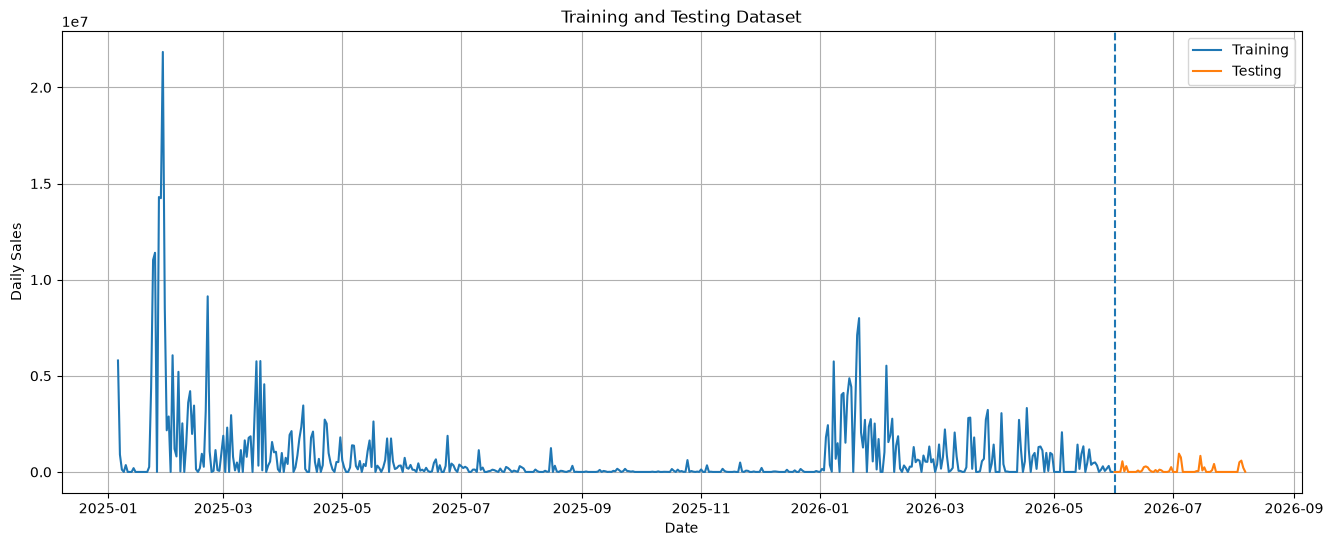

In [11]:
plt.figure(figsize=(16, 6))
plt.plot(train.index, train, label="Training")
plt.plot(test.index, test, label="Testing")
plt.axvline(pd.Timestamp("2026-06-01"), linestyle="--")
plt.title("Training and Testing Dataset")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.show()


## Evaluation helpers

In [12]:
def wape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    denominator = np.sum(np.abs(actual))
    if denominator == 0:
        return np.nan
    return np.sum(np.abs(actual - predicted)) / denominator * 100

def evaluate_model(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    model_wape = wape(actual, predicted)

    print(model_name)
    print("-" * 30)
    print(f"Mean Absolute Error: {mae:,.2f}")
    print(f"Root Mean Squared Error: {rmse:,.2f}")
    print(f"Weighted Absolute Percentage Error: {model_wape:.2f}%")


## Naive baseline

In [13]:
naive_predictions = np.repeat(train.iloc[-1], len(test))
evaluate_model(test, naive_predictions, "Naive Baseline")


Naive Baseline
------------------------------
Mean Absolute Error: 107,512.65
Root Mean Squared Error: 236,370.31
Weighted Absolute Percentage Error: 100.00%


## Augmented Dickey-Fuller stationarity test

In [14]:
def adf_test(series):
    result = adfuller(series.dropna())
    print("ADF Statistic:", result[0])
    print("p-value      :", result[1])

    if result[1] <= 0.05:
        print("Series appears STATIONARY")
    else:
        print("Series appears NON-STATIONARY")

adf_test(train)


ADF Statistic: -5.950858897258781
p-value      : 2.1489295224785587e-07
Series appears STATIONARY


## First differencing

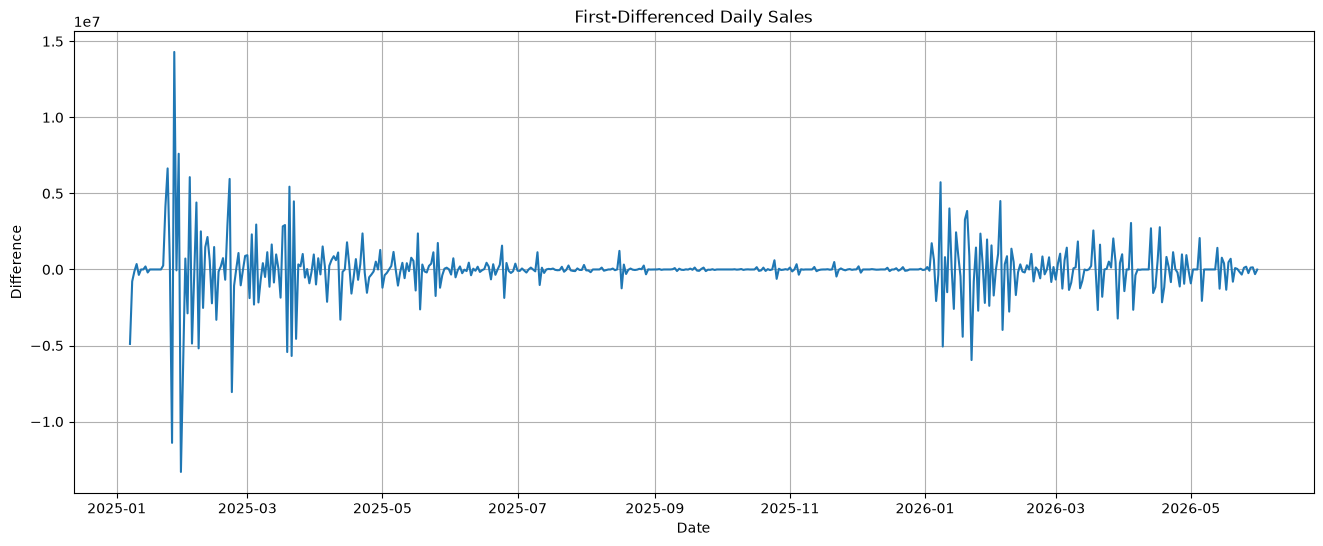

ADF Statistic: -9.65814865900353
p-value      : 1.3763190725925398e-16
Series appears STATIONARY


In [15]:
train_diff_1 = train.diff().dropna()

plt.figure(figsize=(16, 6))
plt.plot(train_diff_1)
plt.title("First-Differenced Daily Sales")
plt.xlabel("Date")
plt.ylabel("Difference")
plt.grid(True)
plt.show()

adf_test(train_diff_1)


## AutoCorrelation Function

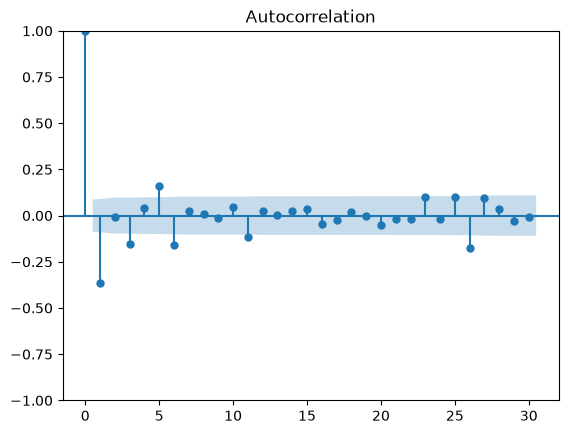

In [16]:
plot_acf(train_diff_1, lags=30)
plt.show()


## Partial AutoCorrelation Function

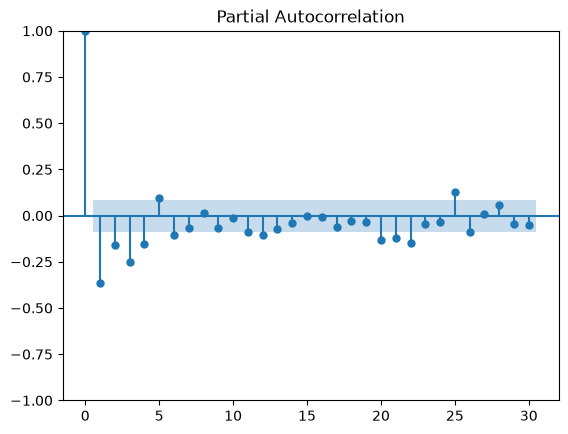

In [17]:
plot_pacf(train_diff_1, lags=30, method="ywm")
plt.show()


## Search for ARIMA(p, d, q)

This checks `p=0..5`, `d=0..1`, and `q=0..5`, then ranks models using the **Akaike Information Criterion (AIC)**.


In [18]:
p_values = range(0, 6)
d_values = range(0, 2)
q_values = range(0, 6)

results = []

for p, d, q in itertools.product(p_values, d_values, q_values):
    try:
        model = ARIMA(train, order=(p, d, q))
        fitted_model = model.fit()

        results.append({
            "p": p,
            "d": d,
            "q": q,
            "AIC": fitted_model.aic
        })
    except Exception:
        pass

results_df = pd.DataFrame(results).sort_values("AIC")
results_df.head(10)


c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

,p,d,q,AIC
69,5,1,3,15967.742972
70,5,1,4,15969.992547
71,5,1,5,15971.910870
68,5,1,2,15972.923242
57,4,1,3,15978.838926
47,3,1,5,15980.780311
45,3,1,3,15982.879665
46,3,1,4,15983.309536
58,4,1,4,15986.582129
34,2,1,4,15986.711050


## Pick the best parameter combination

In [19]:
best_row = results_df.iloc[0]

best_p = int(best_row["p"])
best_d = int(best_row["d"])
best_q = int(best_row["q"])

print(f"Best ARIMA order = ({best_p}, {best_d}, {best_q})")
print(f"AIC = {best_row['AIC']:.2f}")


Best ARIMA order = (5, 1, 3)
AIC = 15967.74


## Train ARIMA

In [20]:
arima_model = ARIMA(train, order=(best_p, best_d, best_q))
arima_result = arima_model.fit()
print(arima_result.summary())


                               SARIMAX Results                                
Dep. Variable:      daily_sales_total   No. Observations:                  511
Model:                 ARIMA(5, 1, 3)   Log Likelihood               -7974.871
Date:                Sat, 08 Aug 2026   AIC                          15967.743
Time:                        13:07:51   BIC                          16005.853
Sample:                    01-06-2025   HQIC                         15982.684
                         - 05-31-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3460      0.091     -3.809      0.000      -0.524      -0.168
ar.L2          0.0277      0.118      0.235      0.814      -0.204       0.259
ar.L3          0.2193      0.052      4.252      0.0

## Forecast the full test period

In [21]:
forecast_result = arima_result.get_forecast(steps=len(test))
arima_predictions = forecast_result.predicted_mean
arima_predictions.index = test.index

# Revenue should not be negative.
arima_predictions_clipped = arima_predictions.clip(lower=0)

arima_predictions_clipped.head()


sale_date
2026-06-01    161194.586083
2026-06-02    345144.457170
2026-06-03    375548.332144
2026-06-04    335502.974487
2026-06-05    413322.248818
Freq: D, Name: predicted_mean, dtype: float64

## Evaluate ARIMA

In [22]:
evaluate_model(test, arima_predictions_clipped, "ARIMA")


ARIMA
------------------------------
Mean Absolute Error: 471,237.23
Root Mean Squared Error: 493,763.73
Weighted Absolute Percentage Error: 438.31%


## Compare actual, naive, and ARIMA

In [23]:
comparison = pd.DataFrame({
    "actual": test,
    "naive": naive_predictions,
    "arima": arima_predictions_clipped
})
comparison.head(20)


,actual,naive,arima
sale_date,,,
2026-06-01,0.00,0.0,161194.586083
2026-06-02,0.00,0.0,345144.457170
2026-06-03,0.00,0.0,375548.332144
2026-06-04,15145.20,0.0,335502.974487
2026-06-05,556387.68,0.0,413322.248818
2026-06-06,30819.60,0.0,455943.223495
2026-06-07,303672.60,0.0,480501.542482
2026-06-08,0.00,0.0,491045.191105
2026-06-09,0.00,0.0,500170.747972


## Plot ARIMA versus actual

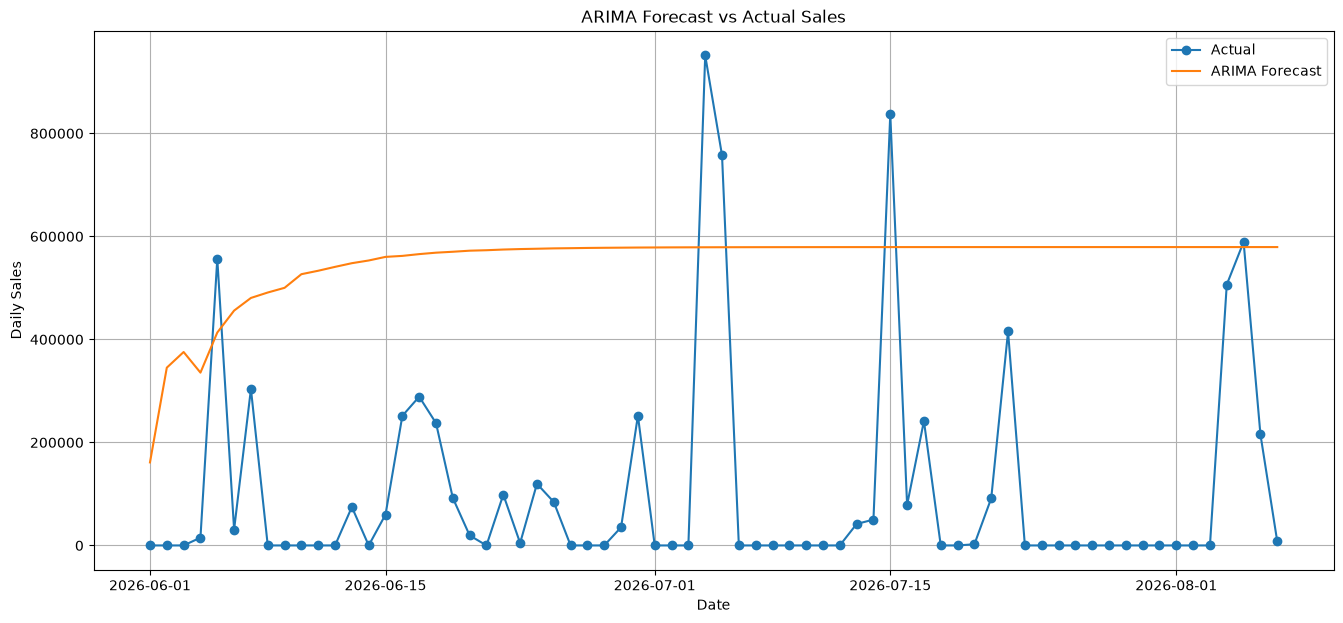

In [24]:
plt.figure(figsize=(16, 7))
plt.plot(test.index, test, label="Actual", marker="o")
plt.plot(test.index, arima_predictions_clipped, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.show()


## Plot actual versus naive versus ARIMA

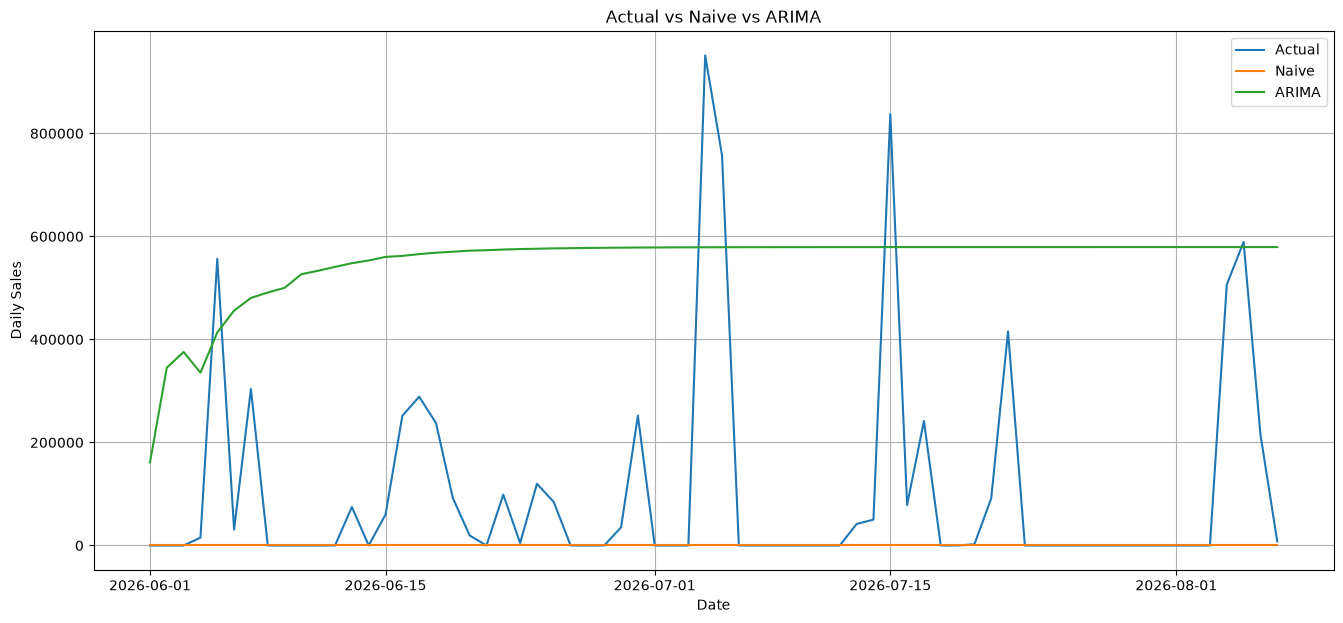

In [25]:
plt.figure(figsize=(16, 7))
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, naive_predictions, label="Naive")
plt.plot(test.index, arima_predictions_clipped, label="ARIMA")
plt.title("Actual vs Naive vs ARIMA")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.show()


## Metrics comparison table

In [26]:
def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE": wape(actual, predicted)
    }

metrics_df = pd.DataFrame(
    [
        get_metrics(test, naive_predictions),
        get_metrics(test, arima_predictions_clipped)
    ],
    index=["Naive", "ARIMA"]
)

metrics_df


,MAE,RMSE,WAPE
Naive,107512.652941,236370.308394,100.000000
ARIMA,471237.233551,493763.731727,438.308628


## Residual analysis

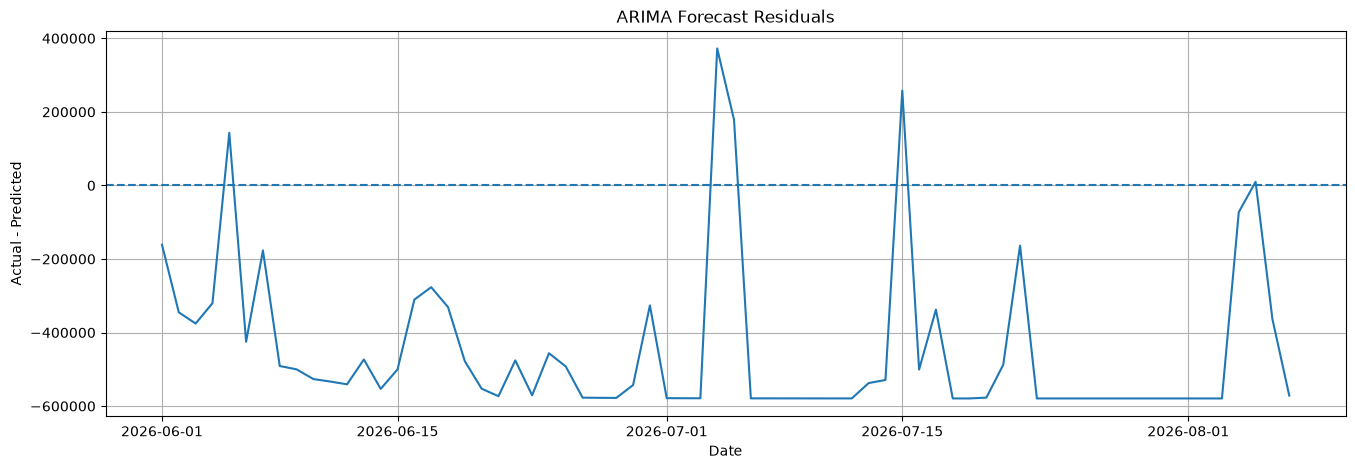

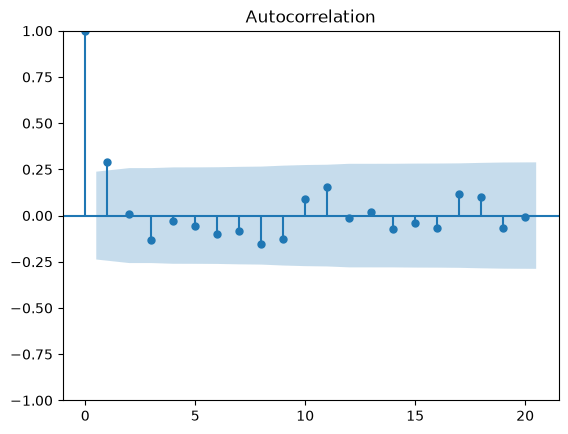

In [27]:
residuals = test - arima_predictions_clipped

plt.figure(figsize=(16, 5))
plt.plot(residuals)
plt.axhline(0, linestyle="--")
plt.title("ARIMA Forecast Residuals")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted")
plt.grid(True)
plt.show()

plot_acf(residuals.dropna(), lags=20)
plt.show()


## Walk-forward validation

In [28]:
history = list(train.values)
walk_forward_predictions = []

for actual_value in test.values:
    model = ARIMA(history, order=(best_p, best_d, best_q))
    fitted = model.fit()

    prediction = fitted.forecast(steps=1)[0]
    prediction = max(prediction, 0)

    walk_forward_predictions.append(prediction)
    history.append(actual_value)

walk_forward_predictions = pd.Series(
    walk_forward_predictions,
    index=test.index
)

evaluate_model(
    test,
    walk_forward_predictions,
    "Walk-Forward ARIMA"
)


Walk-Forward ARIMA
------------------------------
Mean Absolute Error: 183,452.77
Root Mean Squared Error: 233,015.55
Weighted Absolute Percentage Error: 170.63%


## Plot walk-forward forecast

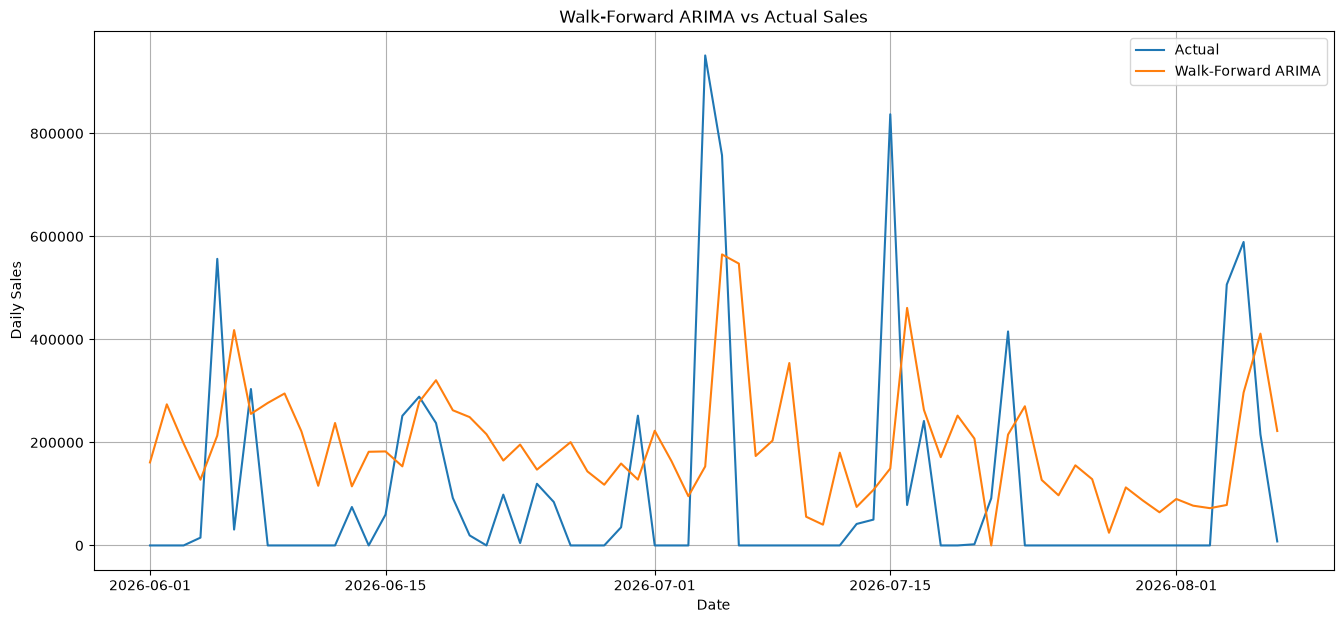

In [29]:
plt.figure(figsize=(16, 7))
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, walk_forward_predictions, label="Walk-Forward ARIMA")
plt.title("Walk-Forward ARIMA vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.show()


## Retrain on all historical data

In [30]:
full_series = df["daily_sales_total"]

final_model = ARIMA(
    full_series,
    order=(best_p, best_d, best_q)
)

final_result = final_model.fit()
print(final_result.summary())


                               SARIMAX Results                                
Dep. Variable:      daily_sales_total   No. Observations:                  579
Model:                 ARIMA(5, 1, 3)   Log Likelihood               -9002.794
Date:                Sat, 08 Aug 2026   AIC                          18023.588
Time:                        13:33:07   BIC                          18062.824
Sample:                    01-06-2025   HQIC                         18038.887
                         - 08-07-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3479      0.080     -4.346      0.000      -0.505      -0.191
ar.L2          0.0262      0.104      0.251      0.802      -0.178       0.230
ar.L3          0.2193      0.045      4.829      0.0

## Forecast the next 30 days

In [31]:
future_forecast = final_result.get_forecast(steps=30)
future_mean = future_forecast.predicted_mean.clip(lower=0)
confidence_interval = future_forecast.conf_int()

future_dates = pd.date_range(
    start=df.index.max() + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

future_df = pd.DataFrame({
    "date": future_dates,
    "predicted_sales": future_mean.values,
    "lower_bound": confidence_interval.iloc[:, 0].values,
    "upper_bound": confidence_interval.iloc[:, 1].values
})

future_df["lower_bound"] = future_df["lower_bound"].clip(lower=0)
future_df


,date,predicted_sales,lower_bound,upper_bound
0,2026-08-08,142365.740111,0.0,2.978155e+06
1,2026-08-09,286080.918240,0.0,3.386369e+06
2,2026-08-10,249871.805866,0.0,3.505886e+06
3,2026-08-11,180641.400944,0.0,3.464302e+06
4,2026-08-12,208899.002422,0.0,3.565556e+06
5,2026-08-13,241143.545466,0.0,3.723891e+06
6,2026-08-14,242283.833374,0.0,3.741189e+06
7,2026-08-15,230384.112265,0.0,3.759913e+06
8,2026-08-16,230341.926141,0.0,3.778982e+06
9,2026-08-17,241489.629226,0.0,3.809405e+06


## Plot recent history plus 30-day forecast

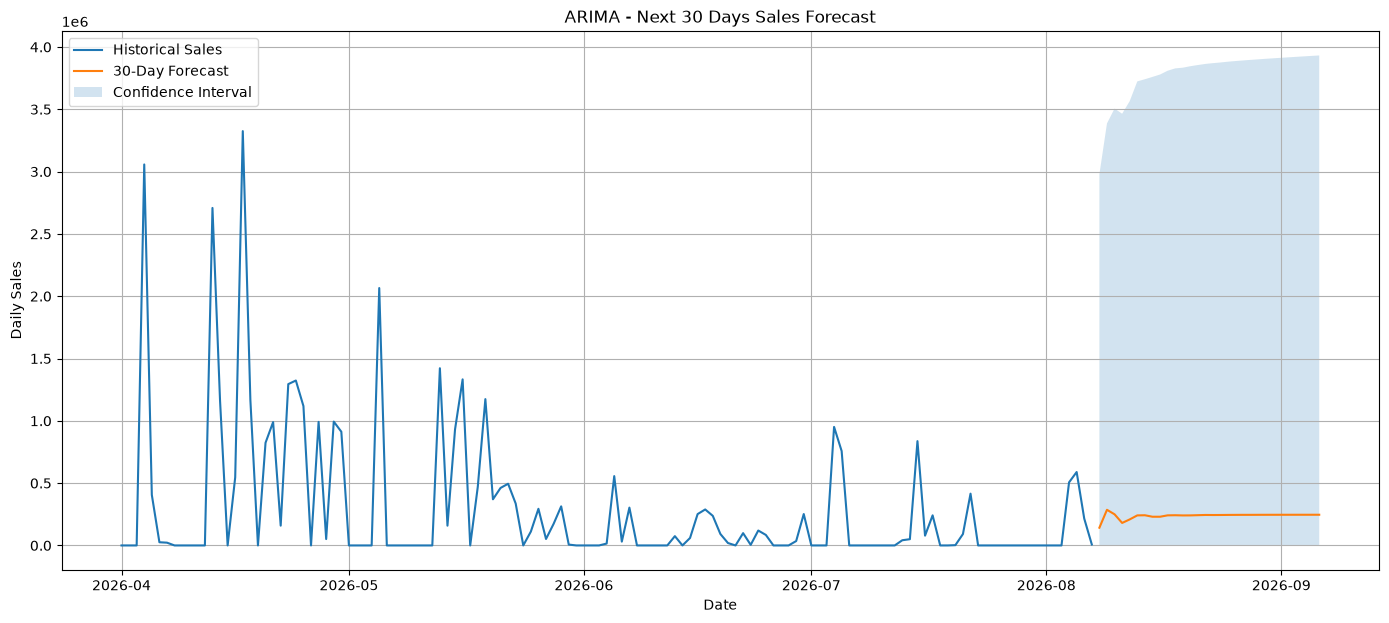

In [32]:
plt.figure(figsize=(17, 7))

recent_history = full_series.loc["2026-04-01":]

plt.plot(recent_history.index, recent_history, label="Historical Sales")
plt.plot(future_df["date"], future_df["predicted_sales"], label="30-Day Forecast")

plt.fill_between(
    future_df["date"],
    future_df["lower_bound"],
    future_df["upper_bound"],
    alpha=0.2,
    label="Confidence Interval"
)

plt.title("ARIMA - Next 30 Days Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.show()


## Export the forecast

In [33]:
future_df.to_csv("arima_30_day_forecast.csv", index=False)
print("Saved: arima_30_day_forecast.csv")


Saved: arima_30_day_forecast.csv


## Save the trained model

In [34]:
final_result.save("arima_sales_model.pkl")
print("Saved: arima_sales_model.pkl")


Saved: arima_sales_model.pkl


## Load the saved model later

In [35]:
loaded_model = ARIMAResults.load("arima_sales_model.pkl")
print("Saved ARIMA model loaded successfully.")


Saved ARIMA model loaded successfully.


## Final note

This notebook forecasts **daily sales revenue** from `sale_order.amount_total`.

If the real business goal is product-demand forecasting, the next version should usually use `sale_order_line` and forecast product quantities, such as `product_uom_qty`, per product or Stock Keeping Unit (SKU).


In [5]:
weekly_df = (
    df["daily_sales_total"]
    .resample("W")
    .sum()
)

weekly_df.head()

TypeError: Only valid with DatetimeIndex, TimedeltaIndex or PeriodIndex, but got an instance of 'RangeIndex'